# 2 — Main analysis

Reproduce the published numeric-label GLMs, model agreement, fixed-input
variability, category mappings, figures, and supplementary diagnostics.
Run after Notebook 1. Reuse the prepared data and baseline below.

Inputs: `intermediate/s0_data.pkl` and `intermediate/s1_labels.pkl`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from itertools import combinations
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import cohen_kappa_score
from matplotlib.ticker import PercentFormatter

In [2]:
INTERMEDIATE = Path("intermediate")
prepared = pd.read_pickle(INTERMEDIATE / "s0_data.pkl")
classified = pd.read_pickle(INTERMEDIATE / "s1_labels.pkl")
claims = classified["claims"]
descriptions = classified["descriptions"]
labels = classified["labels"]
fixed_labels = classified["fixed_labels"]
fixed_manifest = classified["fixed_manifest"]
original_cube = classified["original_cube"]
fixed_cube = classified["fixed_cube"]
original_ids = classified["original_ids"]
fixed_ids = classified["fixed_ids"]
MODEL_ORDER = classified["model_order"]
LABEL_NAMES = classified["label_names"]
RUNS = classified["runs"]

PERILS, FEATURES = prepared["perils"], prepared["features"]
peril_design = prepared["peril_design"]
baseline = prepared["baseline"]
baseline_predictions = prepared["baseline_predictions"]

## Validation performance

Add the run-specific ordinal score to the peril-only Gamma GLM. Model summaries
average five run-level metrics, rather than scoring an ensemble prediction.
MAE improvement intervals use 5,000 resamples of validation descriptions,
retaining every claim belonging to each sampled description.

In [3]:
def regression_metrics(y, pred, p):
    y, pred = np.asarray(y), np.asarray(pred)
    r2 = 1 - np.square(y - pred).sum() / np.square(y - y.mean()).sum()
    return {
        "r2": r2,
        "adjusted_r2": 1 - (1 - r2) * (len(y) - 1) / (len(y) - p - 1),
        "mae": np.abs(y - pred).mean(),
    }


baseline_valid = claims.query("split == 'validation'")
baseline_validation_errors = (
    baseline_predictions.set_index("claim_row")
    .loc[baseline_valid.claim_row, "abs_error"]
    .to_numpy()
)

model_validation_errors = {model: [] for model in MODEL_ORDER}

fits = {}
validation_prediction_frames = []
performance_rows = []
for model in MODEL_ORDER:
    for run in RUNS:
        feature = labels.query("model == @model and run == @run")[
            ["description_id", "label_value"]
        ]
        data = claims.merge(
            feature, on="description_id", how="left", validate="many_to_one"
        )
        train = data.query("split == 'train'")
        valid = data.query("split == 'validation'")
        feature_cols = PERILS[:-1] + ["label_value"]
        x_train = peril_design.loc[train.index].assign(label_value=train.label_value)
        x_valid = peril_design.loc[valid.index].assign(label_value=valid.label_value)
        fit = sm.GLM(
            train["log_loss"],
            x_train,
            family=sm.families.Gamma(link=sm.families.links.Log()),
        ).fit()
        fits[(model, run)] = fit
        train_pred = fit.predict(x_train)
        valid_pred = fit.predict(x_valid)
        prediction_frame = valid[
            ["claim_row", "description_id", "Loss", "log_loss"]
        ].copy()
        prediction_frame["model"], prediction_frame["run"] = model, run
        prediction_frame["prediction"] = valid_pred.to_numpy()
        validation_prediction_frames.append(prediction_frame)
        model_validation_errors[model].append(
            np.abs(valid["log_loss"].to_numpy() - valid_pred.to_numpy())
        )
        performance_rows.extend(
            [
                {
                    "model": model,
                    "run": run,
                    "split": "train",
                    **regression_metrics(train.log_loss, train_pred, len(feature_cols)),
                },
                {
                    "model": model,
                    "run": run,
                    "split": "validation",
                    **regression_metrics(valid.log_loss, valid_pred, len(feature_cols)),
                },
            ]
        )

performance = pd.DataFrame(performance_rows)
validation_performance = performance.query("split == 'validation'")
performance_summary = validation_performance.groupby("model", as_index=False).agg(
    mean_mae=("mae", "mean"),
    sd_mae=("mae", "std"),
    mean_r2=("r2", "mean"),
    sd_r2=("r2", "std"),
)
performance_summary["model"] = pd.Categorical(
    performance_summary["model"], MODEL_ORDER, ordered=True
)
performance_summary = performance_summary.sort_values("model")
display(performance_summary.round(4))

# Paired percentile bootstrap by unique description (5,000 replicates).
# Positive values mean that the LLM feature lowers validation MAE.
bootstrap_rng = np.random.default_rng(20260812)
bootstrap_rows = []
baseline_validation_mae = baseline_validation_errors.mean()
for model in MODEL_ORDER:
    model_error = np.vstack(model_validation_errors[model]).mean(axis=0)
    improvement = baseline_validation_errors - model_error
    clustered = (
        pd.DataFrame(
            {
                "description_id": baseline_valid["description_id"].to_numpy(),
                "improvement": improvement,
            }
        )
        .groupby("description_id", as_index=False)
        .agg(
            improvement_sum=("improvement", "sum"), claim_count=("improvement", "size")
        )
    )
    boot = np.empty(5_000)
    for b in range(len(boot)):
        sampled = bootstrap_rng.integers(0, len(clustered), size=len(clustered))
        boot[b] = (
            clustered["improvement_sum"].to_numpy()[sampled].sum()
            / clustered["claim_count"].to_numpy()[sampled].sum()
        )
    ci_low, ci_high = np.quantile(boot, [0.025, 0.975])
    point = improvement.mean()
    bootstrap_rows.append(
        {
            "model": model,
            "mean_mae_improvement": point,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "mean_improvement_pct_baseline": 100 * point / baseline_validation_mae,
            "ci_low_pct_baseline": 100 * ci_low / baseline_validation_mae,
            "ci_high_pct_baseline": 100 * ci_high / baseline_validation_mae,
            "bootstrap_unit": "description",
            "bootstrap_replicates": len(boot),
        }
    )

mae_improvement_bootstrap = pd.DataFrame(bootstrap_rows)
display(mae_improvement_bootstrap.round(4))

validation_predictions = pd.concat(validation_prediction_frames, ignore_index=True)

,model,mean_mae,sd_mae,mean_r2,sd_r2
2,GPT-5.6 Sol,0.9906,0.0133,0.4283,0.0125
3,Gemini 3.1 Pro,0.9794,0.0039,0.4356,0.0032
4,Kimi K2.6,1.0037,0.0091,0.4100,0.0078
0,DeepSeek V4 Pro,1.0050,0.0051,0.4137,0.0039
5,Qwen3.5 397B,1.0143,0.0026,0.4046,0.0020
1,GLM-5.2,1.0006,0.0095,0.4151,0.0099


,model,mean_mae_improvement,ci_low,ci_high,mean_improvement_pct_baseline,ci_low_pct_baseline,ci_high_pct_baseline,bootstrap_unit,bootstrap_replicates
0,GPT-5.6 Sol,0.0788,0.0583,0.0987,7.3699,5.4493,9.2279,description,5000
1,Gemini 3.1 Pro,0.0900,0.0681,0.1130,8.4132,6.3642,10.5663,description,5000
2,Kimi K2.6,0.0657,0.0492,0.0832,6.1404,4.6005,7.7790,description,5000
3,DeepSeek V4 Pro,0.0644,0.0463,0.0823,6.0212,4.3279,7.6963,description,5000
4,Qwen3.5 397B,0.0551,0.0398,0.0703,5.1534,3.7220,6.5752,description,5000
5,GLM-5.2,0.0688,0.0509,0.0868,6.4361,4.7565,8.1207,description,5000


## Prescribed labels and ordinal agreement

Prescribe the five-run mode. Ties select the modal category nearest the median;
remaining ties use the first category in the frequency table, as in the paper.
Each unique description receives equal weight. The randomized-batch reruns
combine repeated-inference and neighboring-description variation.

In [4]:
def mean_pairwise_abs(values):
    values = np.asarray(values, dtype=float)
    return np.mean(
        [abs(values[i] - values[j]) for i, j in combinations(range(len(values)), 2)]
    )


within_claim = (
    labels.groupby(["model", "description_id"])["label_value"]
    .agg(list)
    .reset_index(name="values")
)
within_claim["all_same"] = within_claim["values"].map(lambda x: len(set(x)) == 1)
within_claim["any_variation"] = ~within_claim["all_same"]
within_claim["mean_pairwise_abs"] = within_claim["values"].map(mean_pairwise_abs)
within_claim["span_ge_2"] = within_claim["values"].map(lambda x: max(x) - min(x) >= 2)

within_rows = []
for model in MODEL_ORDER:
    sub = labels.query("model == @model")
    wide = sub.pivot(index="description_id", columns="run", values="label_value")
    exacts, kappas = [], []
    for r1, r2 in combinations(RUNS, 2):
        exacts.append((wide[r1] == wide[r2]).mean())
        kappas.append(
            cohen_kappa_score(
                wide[r1], wide[r2], labels=[1, 2, 3, 4, 5], weights="quadratic"
            )
        )
    claim_sub = within_claim.query("model == @model")
    within_rows.append(
        {
            "model": model,
            "all_five_same": claim_sub["all_same"].mean(),
            "average_pairwise_exact_agreement": np.mean(exacts),
            "average_pairwise_weighted_kappa": np.mean(kappas),
            "within_model_distance": claim_sub["mean_pairwise_abs"].mean(),
            "any_run_variation": claim_sub["any_variation"].mean(),
            "span_ge_2": claim_sub["span_ge_2"].mean(),
        }
    )
within = pd.DataFrame(within_rows)


def modal_record(group):
    counts = group["label_value"].value_counts()
    candidates = counts[counts == counts.max()].index.to_numpy()
    median = group["label_value"].median()
    modal_value = int(candidates[np.argmin(np.abs(candidates - median))])
    return pd.Series(
        {
            "modal_value": modal_value,
            "modal_label": LABEL_NAMES[modal_value - 1],
            "modal_count": int(counts.max()),
            "consistency": counts.max() / len(group),
        }
    )


modal = (
    labels.groupby(["model", "description_id"], sort=False)
    .apply(modal_record, include_groups=False)
    .reset_index()
)
modal_wide = modal.pivot(index="description_id", columns="model", values="modal_value")[
    MODEL_ORDER
]

pair_rows = []
between_vectors = {}
for model_a, model_b in combinations(MODEL_ORDER, 2):
    a, b = modal_wide[model_a].to_numpy(), modal_wide[model_b].to_numpy()
    distance = np.abs(a - b)
    key = f"{model_a} | {model_b}"
    between_vectors[key] = distance
    pair_rows.append(
        {
            "model_a": model_a,
            "model_b": model_b,
            "exact_agreement": np.mean(a == b),
            "disagreement_rate": np.mean(a != b),
            "weighted_kappa": cohen_kappa_score(
                a, b, labels=[1, 2, 3, 4, 5], weights="quadratic"
            ),
            "between_model_distance": distance.mean(),
            "differ_by_2_plus": np.mean(distance >= 2),
        }
    )
between = pd.DataFrame(pair_rows)
average_between_modal = np.mean(np.concatenate(list(between_vectors.values())))
average_randomized_within = within_claim["mean_pairwise_abs"].mean()

model_summary = performance_summary.merge(within, on="model")

In [5]:
# Preserve the original bootstrap calculation order for the reported intervals.
RNG = np.random.default_rng(20260812)
BOOTSTRAPS = 1000


def bootstrap_mean_ci(values):
    values = np.asarray(values, dtype=float)
    estimates = np.empty(BOOTSTRAPS)
    for b in range(BOOTSTRAPS):
        estimates[b] = values[RNG.integers(0, len(values), len(values))].mean()
    return np.quantile(estimates, [0.025, 0.975])


bootstrap_rows = []
for model in MODEL_ORDER:
    values = within_claim.query("model == @model")["mean_pairwise_abs"].to_numpy()
    lo, hi = bootstrap_mean_ci(values)
    bootstrap_rows.append(
        {
            "scope": "within",
            "comparison": model,
            "metric": "ordinal_distance",
            "estimate": values.mean(),
            "ci_low": lo,
            "ci_high": hi,
        }
    )

for _, row in between.iterrows():
    key = f"{row.model_a} | {row.model_b}"
    distance = between_vectors[key]
    for metric, values in [
        ("ordinal_distance", distance),
        ("disagreement_rate", distance > 0),
    ]:
        lo, hi = bootstrap_mean_ci(values)
        bootstrap_rows.append(
            {
                "scope": "between",
                "comparison": key,
                "metric": metric,
                "estimate": np.mean(values),
                "ci_low": lo,
                "ci_high": hi,
            }
        )

bootstrap = pd.DataFrame(bootstrap_rows)

## Fixed-input variability

On the same 1,000 descriptions, compare ten within-model run pairs and 25
run combinations for each model pair. Bootstrap intervals use 1,000 resamples
of descriptions. Randomized batching is a separate operational comparison,
not an additive causal decomposition.

In [6]:
fixed_ids = set(fixed_manifest["description_id"])
randomized_sample = labels[labels["description_id"].isin(fixed_ids)].copy()


def claim_pairwise_distances(frame):
    return (
        frame.groupby(["model", "description_id"])["label_value"]
        .agg(list)
        .reset_index(name="values")
        .assign(distance=lambda x: x["values"].map(mean_pairwise_abs))
    )


fixed_within_claim = claim_pairwise_distances(fixed_labels)
randomized_sample_within = claim_pairwise_distances(randomized_sample)

fixed_wide = fixed_labels.pivot(
    index="description_id", columns=["model", "run"], values="label_value"
)
between_fixed_claim = pd.DataFrame(index=fixed_wide.index)
for model_a, model_b in combinations(MODEL_ORDER, 2):
    distances = []
    for run_a in RUNS:
        for run_b in RUNS:
            distances.append(
                (fixed_wide[(model_a, run_a)] - fixed_wide[(model_b, run_b)]).abs()
            )
    between_fixed_claim[f"{model_a} | {model_b}"] = pd.concat(distances, axis=1).mean(
        axis=1
    )
between_fixed_vector = between_fixed_claim.mean(axis=1)


def modal_table(frame):
    return (
        frame.groupby(["model", "description_id"], sort=False)
        .apply(modal_record, include_groups=False)
        .reset_index()
    )


fixed_modal = modal_table(fixed_labels)
randomized_sample_modal = modal[modal["description_id"].isin(fixed_ids)].copy()
fixed_modal_wide = fixed_modal.pivot(
    index="description_id", columns="model", values="modal_value"
)[MODEL_ORDER]
randomized_sample_modal_wide = randomized_sample_modal.pivot(
    index="description_id", columns="model", values="modal_value"
)[MODEL_ORDER]

decomposition_rows = []
for model in MODEL_ORDER:
    fixed_values = fixed_within_claim.query("model == @model").set_index(
        "description_id"
    )["distance"]
    randomized_values = randomized_sample_within.query("model == @model").set_index(
        "description_id"
    )["distance"]
    modal_shift = (fixed_modal_wide[model] - randomized_sample_modal_wide[model]).abs()
    decomposition_rows.append(
        {
            "model": model,
            "fixed_batch_rerun_distance": fixed_values.mean(),
            "randomized_batch_operational_distance": randomized_values.mean(),
            "increment_associated_with_randomized_batching": randomized_values.mean()
            - fixed_values.mean(),
            "fixed_vs_randomized_modal_shift": modal_shift.mean(),
            "fixed_vs_randomized_modal_disagreement": (modal_shift > 0).mean(),
            "fixed_vs_randomized_modal_two_plus": (modal_shift >= 2).mean(),
        }
    )
variation_by_model = pd.DataFrame(decomposition_rows)

fixed_within_vector = fixed_within_claim.groupby("description_id")["distance"].mean()
randomized_within_vector = randomized_sample_within.groupby("description_id")[
    "distance"
].mean()
variation_vectors = {
    "Fixed-batch rerun": fixed_within_vector,
    "Randomized-batch operation": randomized_within_vector,
    "Model change, fixed batch": between_fixed_vector,
}
variation_summary_rows = []
for source, vector in variation_vectors.items():
    lo, hi = bootstrap_mean_ci(vector.to_numpy())
    variation_summary_rows.append(
        {
            "source": source,
            "mean_ordinal_distance": vector.mean(),
            "ci_low": lo,
            "ci_high": hi,
        }
    )
variation_summary = pd.DataFrame(variation_summary_rows)
fixed_rerun_reference = variation_summary.loc[
    variation_summary["source"] == "Fixed-batch rerun", "mean_ordinal_distance"
].iloc[0]
variation_summary["relative_to_fixed_rerun"] = (
    variation_summary["mean_ordinal_distance"] / fixed_rerun_reference
)

display(variation_summary.round(4))

,source,mean_ordinal_distance,ci_low,ci_high,relative_to_fixed_rerun
0,Fixed-batch rerun,0.1054,0.1001,0.1117,1.0000
1,Randomized-batch operation,0.3082,0.2999,0.3172,2.9232
2,"Model change, fixed batch",0.3545,0.3421,0.3667,3.3623


## Severity mappings and similar-performance pairs

Category shares weight unique descriptions equally. Realized losses within
labels use training claims only. The practical-performance rule is an absolute
difference in mean validation MAE below 1% of baseline MAE; it is not an
equivalence test. Also report 0.5% and 2% tolerances.

In [7]:
severity_observed = modal.groupby(
    ["model", "modal_value", "modal_label"], as_index=False
).agg(descriptions=("description_id", "size"))
severity_grid = pd.MultiIndex.from_product(
    [MODEL_ORDER, range(1, 6)], names=["model", "modal_value"]
).to_frame(index=False)
severity_grid["modal_label"] = severity_grid["modal_value"].map(
    lambda value: LABEL_NAMES[value - 1]
)
category_use = severity_grid.merge(
    severity_observed, on=["model", "modal_value", "modal_label"], how="left"
)
category_use["descriptions"] = category_use["descriptions"].fillna(0).astype(int)
category_use["share"] = category_use["descriptions"] / category_use.groupby("model")[
    "descriptions"
].transform("sum")

train_claims = claims.query("split == 'train'")
loss_by_severity = (
    train_claims.merge(modal, on="description_id", how="left", validate="many_to_many")
    .groupby(["model", "modal_value", "modal_label"], as_index=False)
    .agg(
        claims=("Loss", "size"),
        mean_loss=("Loss", "mean"),
        median_loss=("Loss", "median"),
        mean_log_loss=("log_loss", "mean"),
    )
)
severity_mapping = category_use.merge(
    loss_by_severity, on=["model", "modal_value", "modal_label"], how="left"
)

In [8]:
baseline_mae = float(baseline.query("split == 'validation'")["mae"].iloc[0])
mae_map = performance_summary.set_index("model")["mean_mae"].astype(float).to_dict()
equivalence = between.copy()
equivalence["absolute_mae_difference"] = equivalence.apply(
    lambda r: abs(mae_map[r.model_a] - mae_map[r.model_b]), axis=1
)
equivalence["mae_difference_pct_baseline"] = (
    100 * equivalence["absolute_mae_difference"] / baseline_mae
)
equivalence["approximately_equivalent"] = (
    equivalence["absolute_mae_difference"] < 0.01 * baseline_mae
)

threshold_rows = []
for threshold_pct in [0.5, 1.0, 2.0]:
    selected = equivalence.query("mae_difference_pct_baseline < @threshold_pct")
    threshold_rows.append(
        {
            "threshold_pct_baseline_mae": threshold_pct,
            "equivalent_pairs": len(selected),
            "total_pairs": len(equivalence),
            "equivalent_pair_share": len(selected) / len(equivalence),
            "min_disagreement_rate": selected["disagreement_rate"].min(),
            "median_disagreement_rate": selected["disagreement_rate"].median(),
            "max_disagreement_rate": selected["disagreement_rate"].max(),
            "equivalent_model_pairs": "; ".join(
                selected.apply(lambda row: f"{row.model_a} | {row.model_b}", axis=1)
            ),
        }
    )
equivalence_threshold_sensitivity = pd.DataFrame(threshold_rows)
display(
    equivalence.sort_values(
        ["approximately_equivalent", "disagreement_rate"], ascending=[False, False]
    ).round(4)
)
display(equivalence_threshold_sensitivity.round(4))

,model_a,model_b,exact_agreement,disagreement_rate,weighted_kappa,between_model_distance,differ_by_2_plus,absolute_mae_difference,mae_difference_pct_baseline,approximately_equivalent
12,DeepSeek V4 Pro,Qwen3.5 397B,0.7529,0.2471,0.7337,0.2522,0.0049,0.0093,0.8679,True
11,Kimi K2.6,GLM-5.2,0.7610,0.2390,0.7412,0.2416,0.0021,0.0032,0.2957,True
13,DeepSeek V4 Pro,GLM-5.2,0.7670,0.2330,0.7641,0.2352,0.0019,0.0044,0.4149,True
4,GPT-5.6 Sol,GLM-5.2,0.7947,0.2053,0.7827,0.2062,0.0006,0.0100,0.9338,True
10,Kimi K2.6,Qwen3.5 397B,0.8004,0.1996,0.7689,0.2015,0.0019,0.0106,0.9870,True
9,Kimi K2.6,DeepSeek V4 Pro,0.8006,0.1994,0.7880,0.2013,0.0019,0.0013,0.1192,True
0,GPT-5.6 Sol,Gemini 3.1 Pro,0.5910,0.4090,0.6972,0.4132,0.0043,0.0112,1.0433,False
8,Gemini 3.1 Pro,GLM-5.2,0.6002,0.3998,0.6957,0.4053,0.0053,0.0211,1.9771,False
6,Gemini 3.1 Pro,DeepSeek V4 Pro,0.6689,0.3311,0.7403,0.3369,0.0058,0.0256,2.3920,False
3,GPT-5.6 Sol,Qwen3.5 397B,0.6719,0.3281,0.6652,0.3320,0.0036,0.0237,2.2166,False


,threshold_pct_baseline_mae,equivalent_pairs,total_pairs,equivalent_pair_share,min_disagreement_rate,median_disagreement_rate,max_disagreement_rate,equivalent_model_pairs
0,0.5,3,15,0.2000,0.1994,0.2330,0.2390,Kimi K2.6 | DeepSeek V4 Pro; Kimi K2.6 | GLM-5...
1,1.0,6,15,0.4000,0.1994,0.2192,0.2471,GPT-5.6 Sol | GLM-5.2; Kimi K2.6 | DeepSeek V4...
2,2.0,11,15,0.7333,0.1994,0.2390,0.4090,GPT-5.6 Sol | Gemini 3.1 Pro; GPT-5.6 Sol | Ki...


## Weighted validation agreement

Quadratic-weighted kappa is primary. Exact disagreement, ordinal distance, and
larger jumps are complementary measures. Validation weights count claims or
sum their paid losses. The same 1,000 description-cluster bootstrap draws are
used across pairs and validation weights; intervals condition on the saved labels.

In [9]:
AGREEMENT_BOOTSTRAPS = 1000
agreement_rng = np.random.default_rng(20261107)
validation_clusters = (
    claims.loc[claims.split.eq("validation")]
    .groupby("description_id", sort=True)
    .agg(claim_weight=("Loss", "size"), loss_weight=("Loss", "sum"))
)

all_ids = modal_wide.index
valid_ids = validation_clusters.index
all_draws = agreement_rng.multinomial(
    len(all_ids), np.full(len(all_ids), 1 / len(all_ids)), size=AGREEMENT_BOOTSTRAPS
)
valid_draws = agreement_rng.multinomial(
    len(valid_ids),
    np.full(len(valid_ids), 1 / len(valid_ids)),
    size=AGREEMENT_BOOTSTRAPS,
)
populations = [
    ("unique_descriptions", all_ids, np.ones(len(all_ids)), all_draws),
    (
        "validation_claim_weighted",
        valid_ids,
        validation_clusters.claim_weight.to_numpy(),
        valid_draws,
    ),
    (
        "validation_loss_weighted",
        valid_ids,
        validation_clusters.loss_weight.to_numpy(),
        valid_draws,
    ),
]


def agreement_from_sums(sums):
    """Sufficient statistics preserve weighted marginals in each bootstrap draw."""
    total = sums[..., 0]
    mean_a, mean_b = sums[..., 1] / total, sums[..., 2] / total
    expected_squared = (sums[..., 3] + sums[..., 4]) / total - 2 * mean_a * mean_b
    return np.stack(
        [
            1 - (sums[..., 5] / total) / expected_squared,
            sums[..., 6] / total,
            sums[..., 7] / total,
            sums[..., 8] / total,
        ],
        axis=-1,
    )


metric_names = [
    "weighted_kappa",
    "disagreement_rate",
    "mean_ordinal_distance",
    "two_plus_rate",
]
agreement_rows = []
for population, ids, weight, draws in populations:
    values = modal_wide.reindex(ids)
    for model_a, model_b in combinations(MODEL_ORDER, 2):
        a, b = (
            values[model_a].to_numpy(dtype=float),
            values[model_b].to_numpy(dtype=float),
        )
        distance = np.abs(a - b)
        sufficient = weight[:, None] * np.column_stack(
            [
                np.ones(len(ids)),
                a,
                b,
                a * a,
                b * b,
                distance**2,
                distance > 0,
                distance,
                distance >= 2,
            ]
        )
        point = agreement_from_sums(sufficient.sum(axis=0))
        boot = agreement_from_sums(draws @ sufficient)
        ci_low, ci_high = np.quantile(boot, [0.025, 0.975], axis=0)
        # Independent library check on every observed weighted cross-tabulation.
        row = {
            "population": population,
            "model_a": model_a,
            "model_b": model_b,
            "unique_descriptions": len(ids),
            "total_weight": float(weight.sum()),
        }
        for j, metric in enumerate(metric_names):
            row[metric], row[metric + "_ci_low"], row[metric + "_ci_high"] = (
                point[j],
                ci_low[j],
                ci_high[j],
            )
        agreement_rows.append(row)

agreement_weighted = pd.DataFrame(agreement_rows).merge(
    equivalence[
        [
            "model_a",
            "model_b",
            "approximately_equivalent",
            "mae_difference_pct_baseline",
        ]
    ],
    on=["model_a", "model_b"],
    validate="many_to_one",
)
original = agreement_weighted.query("population == 'unique_descriptions'").merge(
    between,
    on=["model_a", "model_b"],
    suffixes=("_new", "_original"),
    validate="one_to_one",
)
central_agreement = agreement_weighted.loc[
    agreement_weighted.approximately_equivalent
].copy()
display(
    central_agreement[
        [
            "population",
            "model_a",
            "model_b",
            "weighted_kappa",
            "weighted_kappa_ci_low",
            "weighted_kappa_ci_high",
            "disagreement_rate",
            "disagreement_rate_ci_low",
            "disagreement_rate_ci_high",
            "mean_ordinal_distance",
            "two_plus_rate",
        ]
    ].round(4)
)

,population,model_a,model_b,weighted_kappa,weighted_kappa_ci_low,weighted_kappa_ci_high,disagreement_rate,disagreement_rate_ci_low,disagreement_rate_ci_high,mean_ordinal_distance,two_plus_rate
4,unique_descriptions,GPT-5.6 Sol,GLM-5.2,0.7827,0.7691,0.7964,0.2053,0.1942,0.2166,0.2062,0.0006
9,unique_descriptions,Kimi K2.6,DeepSeek V4 Pro,0.7880,0.7739,0.8011,0.1994,0.1872,0.2109,0.2013,0.0019
10,unique_descriptions,Kimi K2.6,Qwen3.5 397B,0.7689,0.7538,0.7833,0.1996,0.1883,0.2111,0.2015,0.0019
11,unique_descriptions,Kimi K2.6,GLM-5.2,0.7412,0.7262,0.7565,0.2390,0.2273,0.2510,0.2416,0.0021
12,unique_descriptions,DeepSeek V4 Pro,Qwen3.5 397B,0.7337,0.7182,0.7482,0.2471,0.2356,0.2601,0.2522,0.0049
13,unique_descriptions,DeepSeek V4 Pro,GLM-5.2,0.7641,0.7510,0.7774,0.2330,0.2219,0.2450,0.2352,0.0019
19,validation_claim_weighted,GPT-5.6 Sol,GLM-5.2,0.7895,0.7604,0.8150,0.2146,0.1894,0.2420,0.2146,0.0000
24,validation_claim_weighted,Kimi K2.6,DeepSeek V4 Pro,0.7815,0.7539,0.8081,0.2368,0.2094,0.2645,0.2377,0.0010
25,validation_claim_weighted,Kimi K2.6,Qwen3.5 397B,0.7577,0.7264,0.7861,0.2358,0.2080,0.2640,0.2368,0.0010
26,validation_claim_weighted,Kimi K2.6,GLM-5.2,0.7370,0.7046,0.7646,0.2647,0.2370,0.2957,0.2666,0.0019


## Disagreement when both models prescribe their label in at least four runs

In [10]:
value_wide = modal.pivot(index="description_id", columns="model", values="modal_value")[
    MODEL_ORDER
]
count_wide = modal.pivot(index="description_id", columns="model", values="modal_count")[
    MODEL_ORDER
]
stable_mask = count_wide >= 4

stable_rows = []
for description_id in value_wide.index:
    stable_models = stable_mask.columns[stable_mask.loc[description_id]].tolist()
    if len(stable_models) < 2:
        continue
    values = value_wide.loc[description_id, stable_models]
    spread = int(values.max() - values.min())
    if spread >= 2:
        stable_rows.append(
            {
                "description_id": description_id,
                "stable_model_count": len(stable_models),
                "stable_spread": spread,
            }
        )

stable_set = pd.DataFrame(stable_rows)
description_loss = claims.groupby(
    ["description_id", "Description"], as_index=False
).agg(median_loss=("Loss", "median"), max_loss=("Loss", "max"))
stable_set = stable_set.merge(description_loss, on="description_id", how="left")
for model in MODEL_ORDER:
    model_modal = modal.query("model == @model").set_index("description_id")
    stable_set[model] = stable_set["description_id"].map(
        lambda d, m=model_modal: (
            f"{m.at[d, 'modal_label']} ({int(m.at[d, 'modal_count'])}/5)"
        )
    )
stable_set = stable_set.sort_values(
    ["stable_spread", "median_loss"], ascending=[False, False]
)
representative = stable_set.head(15)


stable_pair_rows = []
for model_a, model_b in combinations(MODEL_ORDER, 2):
    a = modal.query("model == @model_a")[
        ["description_id", "modal_value", "modal_count"]
    ].rename(columns={"modal_value": "value_a", "modal_count": "count_a"})
    b = modal.query("model == @model_b")[
        ["description_id", "modal_value", "modal_count"]
    ].rename(columns={"modal_value": "value_b", "modal_count": "count_b"})
    joined = a.merge(b, on="description_id", validate="one_to_one")
    jointly_stable = joined.query("count_a >= 4 and count_b >= 4").copy()
    distance = (jointly_stable["value_a"] - jointly_stable["value_b"]).abs()
    disagreements = distance[distance > 0]
    stable_pair_rows.append(
        {
            "model_a": model_a,
            "model_b": model_b,
            "jointly_stable_descriptions": len(jointly_stable),
            "jointly_stable_share": len(jointly_stable) / len(descriptions),
            "disagreement_among_jointly_stable": (distance > 0).mean(),
            "one_category_among_disagreements": (disagreements == 1).mean()
            if len(disagreements)
            else 0,
            "two_plus_among_disagreements": (disagreements >= 2).mean()
            if len(disagreements)
            else 0,
        }
    )

stable_pairwise = pd.DataFrame(stable_pair_rows)

display(
    stable_pairwise[
        [
            "model_a",
            "model_b",
            "jointly_stable_share",
            "disagreement_among_jointly_stable",
        ]
    ].round(4)
)
display(
    stable_set.loc[
        stable_set.Description.eq("surveillance system missing"),
        ["Description", *MODEL_ORDER],
    ]
)

,model_a,model_b,jointly_stable_share,disagreement_among_jointly_stable
0,GPT-5.6 Sol,Gemini 3.1 Pro,0.5714,0.3593
1,GPT-5.6 Sol,Kimi K2.6,0.5768,0.1564
2,GPT-5.6 Sol,DeepSeek V4 Pro,0.5525,0.1092
3,GPT-5.6 Sol,Qwen3.5 397B,0.5085,0.2302
4,GPT-5.6 Sol,GLM-5.2,0.5665,0.0726
5,Gemini 3.1 Pro,Kimi K2.6,0.5793,0.2087
6,Gemini 3.1 Pro,DeepSeek V4 Pro,0.5482,0.2361
7,Gemini 3.1 Pro,Qwen3.5 397B,0.5134,0.2130
8,Gemini 3.1 Pro,GLM-5.2,0.5356,0.3591
9,Kimi K2.6,DeepSeek V4 Pro,0.5650,0.0713


,Description,GPT-5.6 Sol,Gemini 3.1 Pro,Kimi K2.6,DeepSeek V4 Pro,Qwen3.5 397B,GLM-5.2
4,surveillance system missing,medium (5/5),low (3/5),low (4/5),high (4/5),medium (4/5),medium (5/5)


## Manuscript figures

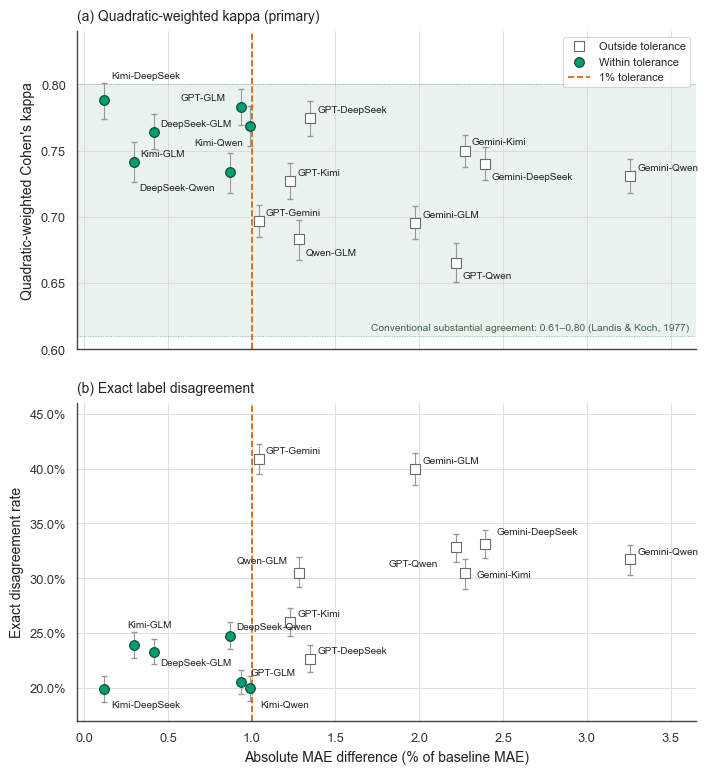

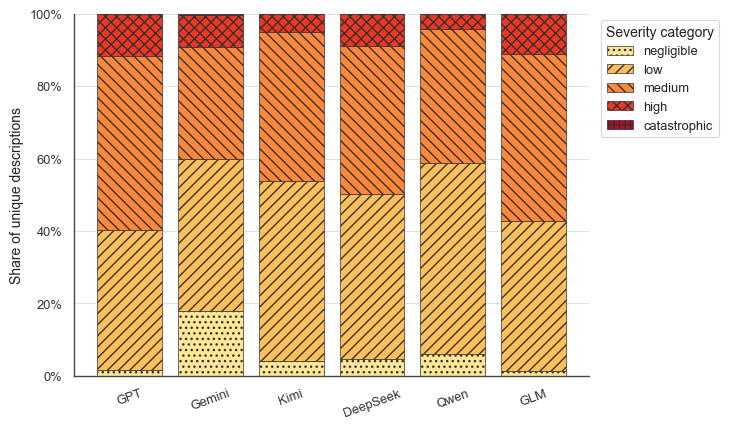

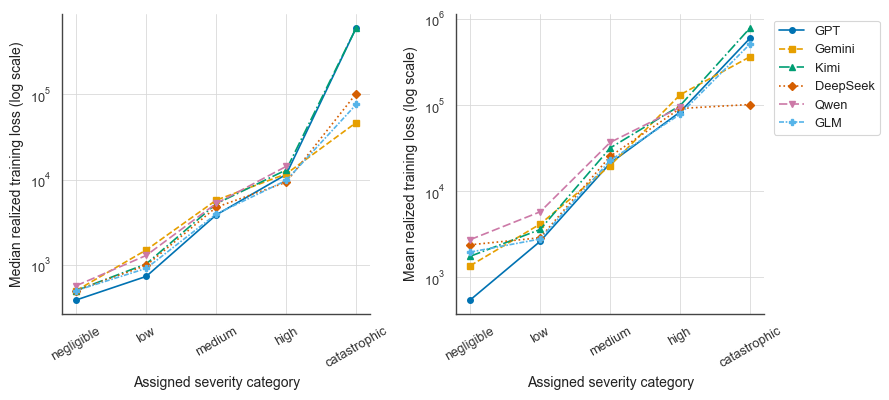

In [11]:
MODELS = [
    "GPT-5.6 Sol",
    "Gemini 3.1 Pro",
    "Kimi K2.6",
    "DeepSeek V4 Pro",
    "Qwen3.5 397B",
    "GLM-5.2",
]
LABELS = ["negligible", "low", "medium", "high", "catastrophic"]
SHORT = {
    "GPT-5.6 Sol": "GPT",
    "Gemini 3.1 Pro": "Gemini",
    "Kimi K2.6": "Kimi",
    "DeepSeek V4 Pro": "DeepSeek",
    "Qwen3.5 397B": "Qwen",
    "GLM-5.2": "GLM",
}
MODEL_COLORS = {
    "GPT-5.6 Sol": "#0072B2",  # blue
    "Gemini 3.1 Pro": "#E69F00",  # orange
    "Kimi K2.6": "#009E73",  # bluish green
    "DeepSeek V4 Pro": "#D55E00",  # vermillion
    "Qwen3.5 397B": "#CC79A7",  # reddish purple
    "GLM-5.2": "#56B4E9",  # sky blue
}
OPERATION_COLORS = ["#56B4E9", "#E69F00", "#D55E00"]
SEVERITY_COLORS = [
    plt.get_cmap("YlOrRd")(value) for value in np.linspace(0.16, 0.86, 5)
]


def show(fig):
    display(fig)
    plt.close(fig)


sns.set_theme(style="whitegrid", context="paper", font_scale=1.05)
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#444444",
        "axes.labelcolor": "#222222",
        "text.color": "#222222",
        "xtick.color": "#333333",
        "ytick.color": "#333333",
        "grid.color": "#D9D9D9",
        "grid.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# Central figure: show ordinal agreement and exact disagreement on aligned MAE axes.
# Landis & Koch (1977), Biometrics 33:159-174, DOI 10.2307/2529310,
# conventionally describe kappa 0.61-0.80 as substantial; these are descriptive labels.
equiv = equivalence.copy()
ordinal_ci = agreement_weighted.query("population == 'unique_descriptions'")
equiv = equiv.merge(
    ordinal_ci[
        [
            "model_a",
            "model_b",
            "weighted_kappa_ci_low",
            "weighted_kappa_ci_high",
            "disagreement_rate_ci_low",
            "disagreement_rate_ci_high",
        ]
    ],
    on=["model_a", "model_b"],
    validate="one_to_one",
)
fig, axes = plt.subplots(2, 1, figsize=(7.2, 7.8), sharex=True)
within = equiv["approximately_equivalent"]
axes[0].axhspan(0.61, 0.80, color="#EAF3ED", zorder=0)
for boundary in [0.61, 0.80]:
    axes[0].axhline(boundary, color="#9AB7A3", linestyle=":", linewidth=0.7, zorder=1)

kappa_offsets = {
    "Kimi-DeepSeek": (5, 16),
    "GPT-Qwen": (5, -11),
    "Gemini-DeepSeek": (5, -11),
    "Gemini-Kimi": (5, 5),
    "GPT-GLM": (-43, 5),
    "Kimi-Qwen": (-40, -14),
    "DeepSeek-Qwen": (-65, -13),
    "Qwen-GLM": (5, -11),
}
exact_offsets = {
    "Kimi-DeepSeek": (5, -13),
    "Kimi-GLM": (-5, 13),
    "DeepSeek-GLM": (5, -10),
    "DeepSeek-Qwen": (5, 5),
    "GPT-GLM": (7, 5),
    "Kimi-Qwen": (8, -13),
    "GPT-Qwen": (-48, -13),
    "Gemini-DeepSeek": (8, 7),
    "Gemini-Kimi": (8, -3),
    "Qwen-GLM": (-45, 7),
}
for ax, metric, offsets, title in [
    (
        axes[0],
        "weighted_kappa",
        kappa_offsets,
        "(a) Quadratic-weighted kappa (primary)",
    ),
    (axes[1], "disagreement_rate", exact_offsets, "(b) Exact label disagreement"),
]:
    ax.errorbar(
        equiv.mae_difference_pct_baseline,
        equiv[metric],
        yerr=np.vstack(
            [
                equiv[metric] - equiv[metric + "_ci_low"],
                equiv[metric + "_ci_high"] - equiv[metric],
            ]
        ),
        fmt="none",
        ecolor="#999999",
        elinewidth=0.8,
        capsize=2,
        zorder=2,
    )
    ax.scatter(
        equiv.loc[~within, "mae_difference_pct_baseline"],
        equiv.loc[~within, metric],
        s=42,
        marker="s",
        facecolors="white",
        edgecolors="#6B6B6B",
        linewidths=0.8,
        label="Outside tolerance",
        zorder=3,
    )
    ax.scatter(
        equiv.loc[within, "mae_difference_pct_baseline"],
        equiv.loc[within, metric],
        s=48,
        marker="o",
        color="#009E73",
        edgecolors="#174C3B",
        linewidths=0.9,
        label="Within tolerance",
        zorder=4,
    )
    for row in equiv.itertuples():
        label = f"{SHORT[row.model_a]}-{SHORT[row.model_b]}"
        ax.annotate(
            label,
            (row.mae_difference_pct_baseline, getattr(row, metric)),
            xytext=offsets.get(label, (5, 4)),
            textcoords="offset points",
            fontsize=7.2,
        )
    ax.axvline(
        1.0, color="#D55E00", linestyle="--", linewidth=1.2, label="1% tolerance"
    )
    ax.set_title(title, loc="left", fontsize=10, pad=8)
    ax.set_xlim(-0.04, 3.65)

axes[0].set_ylabel("Quadratic-weighted Cohen's kappa")
axes[0].set_ylim(0.60, 0.84)
axes[0].set_yticks([0.60, 0.65, 0.70, 0.75, 0.80])
axes[0].text(
    0.99,
    0.055,
    "Conventional substantial agreement: 0.61–0.80 (Landis & Koch, 1977)",
    transform=axes[0].transAxes,
    ha="right",
    va="bottom",
    fontsize=7.4,
    color="#46624E",
)
axes[0].legend(frameon=True, loc="upper right", fontsize=8)
axes[1].set_ylabel("Exact disagreement rate")
axes[1].set_ylim(0.17, 0.46)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_xlabel("Absolute MAE difference (% of baseline MAE)")
fig.tight_layout(pad=0.9, h_pad=1.7)
show(fig)

# Figure 5a: model-specific category use.
mapping = severity_mapping
use = (
    mapping.pivot(index="model", columns="modal_label", values="share")
    .fillna(0)
    .reindex(index=MODELS, columns=LABELS)
)
fig, ax = plt.subplots(figsize=(7.4, 4.4))
bottom = np.zeros(len(MODELS))
hatches = ["...", "///", "\\\\\\", "xxx", "+++"]
for label, color, hatch in zip(LABELS, SEVERITY_COLORS, hatches):
    values = use[label].to_numpy()
    ax.bar(
        np.arange(len(MODELS)),
        values,
        bottom=bottom,
        label=label,
        color=color,
        edgecolor="#333333",
        linewidth=0.5,
        hatch=hatch,
    )
    bottom += values
ax.set_xticks(np.arange(len(MODELS)), [SHORT[m] for m in MODELS], rotation=20)
ax.set_ylabel("Share of unique descriptions")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(title="Severity category", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
show(fig)

# Figure 5b: empirical loss regions associated with generated labels.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.1), sharex=True)
line_styles = ["-", "--", "-.", ":", (0, (5, 2)), (0, (3, 1, 1, 1))]
markers = ["o", "s", "^", "D", "v", "P"]
for model, line_style, marker in zip(MODELS, line_styles, markers):
    sub = mapping.loc[mapping["model"].eq(model)].sort_values("modal_value")
    axes[0].plot(
        sub["modal_value"],
        sub["median_loss"],
        color=MODEL_COLORS[model],
        linestyle=line_style,
        marker=marker,
        markersize=4,
        label=SHORT[model],
    )
    axes[1].plot(
        sub["modal_value"],
        sub["mean_loss"],
        color=MODEL_COLORS[model],
        linestyle=line_style,
        marker=marker,
        markersize=4,
        label=SHORT[model],
    )
for ax, statistic in zip(axes, ["Median", "Mean"]):
    ax.set_yscale("log")
    ax.set_xticks(range(1, 6), LABELS, rotation=30)
    ax.set_xlabel("Assigned severity category")
    ax.set_ylabel(f"{statistic} realized training loss (log scale)")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
show(fig)

## Ordinal jumps and realized-loss boundaries

In [12]:
def distance_summary(name, distance):
    distance = pd.Series(np.asarray(distance, dtype=int))
    return {
        "comparison": name,
        "comparisons": len(distance),
        "mean_ordinal_distance": distance.mean(),
        "any_difference": (distance > 0).mean(),
        "one_category": (distance == 1).mean(),
        "two_plus_categories": (distance >= 2).mean(),
        "three_plus_categories": (distance >= 3).mean(),
        "max_ordinal_distance": int(distance.max()),
    }


jump_rows, within_vectors, between_vectors_fixed = [], [], []
for model in MODEL_ORDER:
    model_wide = fixed_labels.query("model == @model").pivot(
        index="description_id", columns="run", values="label_value"
    )
    vectors = [(model_wide[a] - model_wide[b]).abs() for a, b in combinations(RUNS, 2)]
    vector = pd.concat(vectors, ignore_index=True)
    within_vectors.append(vector)
    jump_rows.append(distance_summary(model, vector))
jump_rows.append(
    distance_summary(
        "All models: within-model", pd.concat(within_vectors, ignore_index=True)
    )
)

for model_a, model_b in combinations(MODEL_ORDER, 2):
    a = fixed_labels.query("model == @model_a").pivot(
        index="description_id", columns="run", values="label_value"
    )
    b = fixed_labels.query("model == @model_b").pivot(
        index="description_id", columns="run", values="label_value"
    )
    between_vectors_fixed.extend((a[ra] - b[rb]).abs() for ra in RUNS for rb in RUNS)
jump_rows.append(
    distance_summary(
        "Different models: between-model",
        pd.concat(between_vectors_fixed, ignore_index=True),
    )
)
jump_distribution = pd.DataFrame(jump_rows)

equivalent_rows, equivalent_vectors = [], []
for row in equivalence.query("approximately_equivalent").itertuples(index=False):
    distance = (modal_wide[row.model_a] - modal_wide[row.model_b]).abs()
    equivalent_vectors.append(distance)
    equivalent_rows.append(distance_summary(f"{row.model_a} | {row.model_b}", distance))
equivalent_rows.append(
    distance_summary(
        "All pairs within 1% tolerance",
        pd.concat(equivalent_vectors, ignore_index=True),
    )
)
equivalent_jump_distribution = pd.DataFrame(equivalent_rows)

common_labels = severity_mapping.query(
    "modal_label in ['negligible', 'low', 'medium', 'high']"
).dropna(subset=["median_loss"])
boundary_rows = []
for label, group in common_labels.groupby("modal_label", sort=False):
    boundary_rows.append(
        {
            "label": label,
            "min_median_loss": group["median_loss"].min(),
            "max_median_loss": group["median_loss"].max(),
            "median_loss_gap": group["median_loss"].max() - group["median_loss"].min(),
            "median_loss_ratio": group["median_loss"].max()
            / group["median_loss"].min(),
            "mean_loss_gap": group["mean_loss"].max() - group["mean_loss"].min(),
        }
    )
boundary_summary = pd.DataFrame(boundary_rows)

description_loss = train_claims.groupby("description_id", as_index=False).agg(
    median_loss=("Loss", "median")
)
bottom_cutoff = description_loss["median_loss"].quantile(0.20)
negligible_rows = []
for model in MODEL_ORDER:
    mapped = description_loss.merge(
        modal.query("model == @model")[["description_id", "modal_value"]],
        on="description_id",
    )
    bottom = mapped["median_loss"] <= bottom_cutoff
    negligible = mapped["modal_value"] == 1
    negligible_rows.append(
        {
            "model": model,
            "negligible_share_training_descriptions": negligible.mean(),
            "bottom_quintile_covered_by_negligible": (bottom & negligible).sum()
            / bottom.sum(),
            "negligible_descriptions_in_bottom_quintile": (bottom & negligible).sum()
            / negligible.sum(),
            "negligible_median_loss": mapped.loc[negligible, "median_loss"].median(),
            "negligible_maximum_observed_loss": mapped.loc[
                negligible, "median_loss"
            ].max(),
        }
    )
negligible_profile = pd.DataFrame(negligible_rows)

display(jump_distribution.round(4))
display(equivalent_jump_distribution.round(4))
display(boundary_summary.round(2))
display(negligible_profile.round(4))

,comparison,comparisons,mean_ordinal_distance,any_difference,one_category,two_plus_categories,three_plus_categories,max_ordinal_distance
0,GPT-5.6 Sol,10000,0.1342,0.1334,0.1326,0.0008,0.0000,2
1,Gemini 3.1 Pro,10000,0.0818,0.0818,0.0818,0.0000,0.0000,1
2,Kimi K2.6,10000,0.1182,0.1179,0.1176,0.0003,0.0000,2
3,DeepSeek V4 Pro,10000,0.1134,0.1122,0.1110,0.0012,0.0000,2
4,Qwen3.5 397B,10000,0.0566,0.0547,0.0528,0.0019,0.0000,2
5,GLM-5.2,10000,0.1284,0.1274,0.1264,0.0010,0.0000,2
6,All models: within-model,60000,0.1054,0.1046,0.1037,0.0009,0.0000,2
7,Different models: between-model,375000,0.3545,0.3458,0.3374,0.0084,0.0003,4


,comparison,comparisons,mean_ordinal_distance,any_difference,one_category,two_plus_categories,three_plus_categories,max_ordinal_distance
0,GPT-5.6 Sol | GLM-5.2,4690,0.2062,0.2053,0.2047,0.0006,0.0002,3
1,Kimi K2.6 | DeepSeek V4 Pro,4690,0.2013,0.1994,0.1974,0.0019,0.0000,2
2,Kimi K2.6 | Qwen3.5 397B,4690,0.2015,0.1996,0.1977,0.0019,0.0000,2
3,Kimi K2.6 | GLM-5.2,4690,0.2416,0.2390,0.2369,0.0021,0.0004,3
4,DeepSeek V4 Pro | Qwen3.5 397B,4690,0.2522,0.2471,0.2422,0.0049,0.0002,3
5,DeepSeek V4 Pro | GLM-5.2,4690,0.2352,0.2330,0.2311,0.0019,0.0002,3
6,All pairs within 1% tolerance,28140,0.2230,0.2206,0.2183,0.0022,0.0002,3


,label,min_median_loss,max_median_loss,median_loss_gap,median_loss_ratio,mean_loss_gap
0,negligible,388.12,570.27,182.15,1.47,2199.12
1,low,732.51,1494.04,761.53,2.04,3149.03
2,medium,3850.06,5726.39,1876.32,1.49,17007.33
3,high,9295.97,14248.80,4952.83,1.53,53277.37


,model,negligible_share_training_descriptions,bottom_quintile_covered_by_negligible,negligible_descriptions_in_bottom_quintile,negligible_median_loss,negligible_maximum_observed_loss
0,GPT-5.6 Sol,0.0153,0.0535,0.7018,500.00,3887.34
1,Gemini 3.1 Pro,0.1618,0.4485,0.5546,500.00,129762.45
2,Kimi K2.6,0.0370,0.1098,0.5942,500.00,55313.37
3,DeepSeek V4 Pro,0.0391,0.1205,0.6164,500.00,145012.60
4,Qwen3.5 397B,0.0573,0.1419,0.4953,592.49,145012.60
5,GLM-5.2,0.0150,0.0442,0.5893,500.00,50907.65


## Save results

In [13]:
numeric_coefficients = pd.DataFrame(
    [
        {
            "model": model,
            "run": run,
            "term": term,
            "coefficient": float(value),
            "standard_error": float(fit.bse[term]),
        }
        for (model, run), fit in fits.items()
        for term, value in fit.params.items()
    ]
)
pd.to_pickle(
    {
        "baseline_mae": baseline_mae,
        "validation_claims": baseline_valid,
        "model_order": MODEL_ORDER,
        "runs": RUNS,
        "performance": performance,
        "performance_summary": performance_summary,
        "validation_predictions": validation_predictions,
        "coefficients": numeric_coefficients,
        "modal": modal,
        "modal_wide": modal_wide,
        "fixed_modal_wide": fixed_modal_wide,
        "between": between,
        "equivalence": equivalence,
        "mae_intervals": mae_improvement_bootstrap,
        "agreement": agreement_weighted,
        "variation": variation_summary,
        "severity_mapping": severity_mapping,
        "stable_pairwise": stable_pairwise,
        "jumps": jump_distribution,
        "thresholds": equivalence_threshold_sensitivity,
    },
    INTERMEDIATE / "s2_analysis.pkl",
)